In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [30]:


import torch

from torch.utils.data import Subset
import numpy as np
import random

In [29]:
%%writefile data.py
import torch

TRAIN = slice(0, 8000)
VAL = slice(8000, 9000)
TEST = slice(9000, 10000)

def _to_video_tensor(raw):
    raw = torch.as_tensor(raw)
    if raw.ndim == 4:                       
        raw = raw.unsqueeze(2)
    if raw.ndim == 5 and raw.shape[1] == 1 and raw.shape[2] == 20:
        raw = raw.transpose(1, 2)           
    assert raw.ndim == 5 and tuple(raw.shape[1:]) == (20, 1, 64, 64), tuple(raw.shape)
    return raw


def load_moving_mnist(root="./data", download=True):
    
    from torchvision.datasets import MovingMNIST
    ds = MovingMNIST(root=root, split=None, download=download)
    raw = getattr(ds, "data", None)
    if raw is None:                         
        raw = torch.stack([torch.as_tensor(ds[i]) for i in range(len(ds))])
    videos = _to_video_tensor(raw)
    assert videos.shape[0] == 10_000, videos.shape
    return videos.to(torch.float32) / 255.0

def split(videos):
    
    
    assert videos.shape[0] == 10_000
    return videos[TRAIN], videos[VAL], videos[TEST]



Writing data.py


In [31]:
from data import load_moving_mnist, split

videos = load_moving_mnist(root="/kaggle/working/data")
train, val, test = split(videos)
print(tuple(videos.shape), videos.dtype, float(videos.min()), float(videos.max()))
print(tuple(train.shape), tuple(val.shape), tuple(test.shape))


100%|██████████| 819M/819M [00:19<00:00, 42.4MB/s] 


(10000, 20, 1, 64, 64) torch.float32 0.0 1.0
(8000, 20, 1, 64, 64) (1000, 20, 1, 64, 64) (1000, 20, 1, 64, 64)


In [32]:
train

tensor([[[[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],


         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],


         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],


         ...,


         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
     

In [112]:
%%writefile checking.py
import torch

T_FRAMES = 20 

def window_frames(t, k=1):

    inp=[t+k*i for i in range(5)]
    assert inp[-1] <= T_FRAMES, f"input frames {inp} exceed {T_FRAMES}"
    tgt = [t + k * (5 + i) for i in range(5)]
    return inp, [f for f in tgt if f <= T_FRAMES]
def allowed_starts(k, augmented):
    last = T_FRAMES - 6 * k if augmented else T_FRAMES - 9 * k
    return list(range(1, last + 1))


def window(video, t, k=1, dim=0):
    inp, tgt = window_   import importlib, checking
    importlib.reload(checking)frames(t, k)
    take = lambda fs: video.index_select(dim, torch.tensor([f - 1 for f in fs], device=video.device))
    return take(inp), take(tgt)


def M(x):
    mirror=torch.flip(x, dims=(-1,))
    return mirror

def R(x, a=1):
    rotate=torch.rot90(x, k=a, dims=(-2, -1))
    return rotate

def symmetries(x,g):
    y=R(x,g%4)
    if g>=4:
        return M(y)
    return y

def inverse(y,g):
    if g>=4:
        y=M(y)
    return R(y, -(g%4))




Overwriting checking.py


In [34]:
from checking import M, R, symmetries, inverse, window, window_frames, allowed_starts
T_FRAMES = 20
import torch 
def bright(v):
    idx = torch.nonzero(v)
    assert len(idx) == 1
    f, _, r, c = idx[0].tolist()
    return (f, r, c)

def frames_of(k, t=1):
    v = torch.arange(1, 21).float().view(20, 1, 1, 1).expand(20, 1, 64, 64).contiguous() 
    X, Y = window(v, t, k)
    return [int(f) for f in X[:, 0, 0, 0]], [int(f) for f in Y[:, 0, 0, 0]]



torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1


rows = []
d = (M(M(x)) - x).abs().max().item()
rows.append(("(a) max|M(M(x)) - x|", "0", f"{d}  equal={torch.equal(M(M(x)), x)}"))
d = (R(x, 4) - x).abs().max().item()
rows.append(("(b) max|R^4(x) - x|", "0", f"{d}  equal={torch.equal(R(x, 4), x)}"))
lhs, rhs = M(R(M(x))), R(x, -1)
rows.append(("(c) max|MRM(x) - R^-1(x)|", "0", f"{(lhs - rhs).abs().max().item()}  equal={torch.equal(lhs, rhs)}"))
rows.append(("(d) bright pixel of M(p)", "(7, 10, 43)", str(bright(M(p)))))
rows.append(("(e) bright pixel of R(p)", "(7, 43, 10)", str(bright(R(p, 1)))))
for name, k, exp in [("(f) 1x", 1, "1-5 / 6-10"), ("(g) 2x", 2, "1,3,5,7,9 / 11,13,15,17,19"), ("(h) 3x", 3, "1,4,7,10,13 / 16,19")]:
    i, o = frames_of(k)
    rows.append((f"{name} input / target frames", exp, f"{i} / {o}"))

print(f"{'Check':36s} | {'Expected':28s} | Yours")
for r in rows:
    print(f"{r[0]:36s} | {r[1]:28s} | {r[2]}")



Check                                | Expected                     | Yours
(a) max|M(M(x)) - x|                 | 0                            | 0.0  equal=True
(b) max|R^4(x) - x|                  | 0                            | 0.0  equal=True
(c) max|MRM(x) - R^-1(x)|            | 0                            | 0.0  equal=True
(d) bright pixel of M(p)             | (7, 10, 43)                  | (7, 10, 43)
(e) bright pixel of R(p)             | (7, 43, 10)                  | (7, 43, 10)
(f) 1x input / target frames         | 1-5 / 6-10                   | [1, 2, 3, 4, 5] / [6, 7, 8, 9, 10]
(g) 2x input / target frames         | 1,3,5,7,9 / 11,13,15,17,19   | [1, 3, 5, 7, 9] / [11, 13, 15, 17, 19]
(h) 3x input / target frames         | 1,4,7,10,13 / 16,19          | [1, 4, 7, 10, 13] / [16, 19]


In [40]:
%%writefile testing_direction.py
import numpy as np, cv2, matplotlib.pyplot as plt

vids = (train[:50, :, 0].numpy() * 255).round().astype(np.uint8)   

dx_all, dy_all = [], []
for v in vids:
    for s in range(19):                       
        prev, nxt = v[s], v[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        keep = (prev > 51) & (nxt > 51) & (np.hypot(dx, dy) > 0.5)
        dx_all.append(dx[keep]); dy_all.append(dy[keep])

dx = np.concatenate(dx_all); dy = np.concatenate(dy_all)
n_pairs = 50 * 19
speed = np.hypot(dx, dy)
theta = np.degrees(np.arctan2(-dy, dx)) % 360
median = np.median(speed)
print(f"pairs={n_pairs}  kept pixels={len(speed)}  median speed={median:.3f} px/frame")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
edges = np.linspace(0, 360, 19)
ax[0].hist(theta, bins=edges, weights=np.full(len(theta), 1 / len(theta)), edgecolor="k")
ax[0].axhline(1 / 18, color="r", ls="--", label="uniform (1/18)")
ax[0].set_xticks(range(0, 361, 60)); ax[0].set_xlabel("flow direction θ (deg; 0 = right, 90 = up)")
ax[0].set_ylabel("fraction of kept pixels"); ax[0].set_title("(a) direction"); ax[0].legend()

ax[1].hist(speed, bins=20, weights=np.full(len(speed), 1 / len(speed)), edgecolor="k")
ax[1].axvline(median, color="r", ls="--", label=f"median = {median:.3g}")
ax[1].set_xlabel("flow speed (pixels / frame)"); ax[1].set_ylabel("fraction of kept pixels")
ax[1].set_title("(b) speed"); ax[1].legend()
plt.tight_layout(); plt.savefig("figure1.png", dpi=200); plt.show()

h, _ = np.histogram(theta, bins=edges); h = h / h.sum()
print("bin fractions:", np.round(h, 3))
print("max |bin - 1/18| =", np.abs(h - 1/18).max().round(4))
print("share with speed > 3 px/frame:", (speed > 3).mean().round(4))

Writing testing_direction.py


pairs=950  kept pixels=103050  median speed=3.318 px/frame


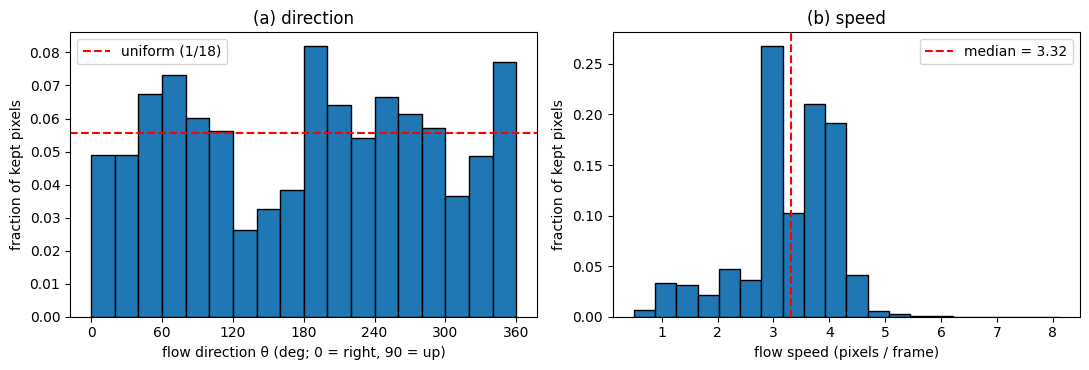

bin fractions: [0.049 0.049 0.067 0.073 0.06  0.056 0.026 0.033 0.038 0.082 0.064 0.054
 0.067 0.061 0.057 0.037 0.049 0.077]
max |bin - 1/18| = 0.0292
share with speed > 3 px/frame: 0.7405


In [38]:
import numpy as np, cv2, matplotlib.pyplot as plt

vids = (train[:50, :, 0].numpy() * 255).round().astype(np.uint8)   

dx_all, dy_all = [], []
for v in vids:
    for s in range(19):                       
        prev, nxt = v[s], v[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        keep = (prev > 51) & (nxt > 51) & (np.hypot(dx, dy) > 0.5)
        dx_all.append(dx[keep]); dy_all.append(dy[keep])

dx = np.concatenate(dx_all); dy = np.concatenate(dy_all)
n_pairs = 50 * 19
speed = np.hypot(dx, dy)
theta = np.degrees(np.arctan2(-dy, dx)) % 360
median = np.median(speed)
print(f"pairs={n_pairs}  kept pixels={len(speed)}  median speed={median:.3f} px/frame")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
edges = np.linspace(0, 360, 19)
ax[0].hist(theta, bins=edges, weights=np.full(len(theta), 1 / len(theta)), edgecolor="k")
ax[0].axhline(1 / 18, color="r", ls="--", label="uniform (1/18)")
ax[0].set_xticks(range(0, 361, 60)); ax[0].set_xlabel("flow direction θ (deg; 0 = right, 90 = up)")
ax[0].set_ylabel("fraction of kept pixels"); ax[0].set_title("(a) direction"); ax[0].legend()

ax[1].hist(speed, bins=20, weights=np.full(len(speed), 1 / len(speed)), edgecolor="k")
ax[1].axvline(median, color="r", ls="--", label=f"median = {median:.3g}")
ax[1].set_xlabel("flow speed (pixels / frame)"); ax[1].set_ylabel("fraction of kept pixels")
ax[1].set_title("(b) speed"); ax[1].legend()
plt.tight_layout(); plt.savefig("figure1.png", dpi=200); plt.show()

h, _ = np.histogram(theta, bins=edges); h = h / h.sum()
print("bin fractions:", np.round(h, 3))
print("max |bin - 1/18| =", np.abs(h - 1/18).max().round(4))
print("share with speed > 3 px/frame:", (speed > 3).mean().round(4))

# delete

In [41]:
edges = np.linspace(0, 360, 19)
def frac(th):
    h, _ = np.histogram(th % 360, bins=edges)
    return h / h.sum()

h0      = frac(theta)
h_mir   = frac(180 - theta)   # mirror: theta -> 180 - theta
h_rot   = frac(theta + 90)    # rotation 90 deg anticlockwise: theta -> theta + 90
tv = lambda a, b: 0.5 * np.abs(a - b).sum()

print("TV(original, mirrored) =", round(tv(h0, h_mir), 4))
print("TV(original, rotated)  =", round(tv(h0, h_rot), 4))
print("TV(original, uniform)  =", round(tv(h0, np.full(18, 1/18)), 4))

TV(original, mirrored) = 0.1325
TV(original, rotated)  = 0.2
TV(original, uniform)  = 0.1095


# end of delete 

# baseline convlstm


In [116]:
%%writefile baselineConvLSTM.py

import torch.nn as nn
import torch.nn.functional as F

import torch


class ConvLSTMCell(nn.Module):
    def __init__(self, in_dims, hidden_dims, kernel_size=3):
        super(ConvLSTMCell, self).__init__()
        self.hidden_dims = hidden_dims
        padding = kernel_size // 2

        # creating one conv for all matrix generation
        self.conv = nn.Conv2d(
            in_dims + hidden_dims, hidden_dims * 4, kernel_size, padding=padding
        )  # includes bias

    def forward(self, x_t, prev):
        h_t, c_t = prev

        # concatenating input and hidden by channel dimension
        x = torch.cat([x_t, h_t], dim=1)
        i, f, o, g = torch.split(self.conv(x), self.hidden_dims, dim=1)
        # forget gate
        
        c = torch.sigmoid(f) * c_t + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)

        return (h, c)

class ConvLSTMForecaster(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.hidden=hidden
        self.cell1 = ConvLSTMCell(16, hidden)      
        
        self.cell2 = ConvLSTMCell(hidden, hidden)      
        self.head = nn.Conv2d(64, 16, kernel_size=1)

    def forward(self, X):                      
        B = X.shape[0]
        states=None
        outputs, pred = [], None
        for tau in range(9):                           
            frame = X[:, tau] if tau < 5 else pred     
            u = F.pixel_unshuffle(frame, 4)
            if states is None:
                z = lambda: u.new_zeros(B, self.hidden, *u.shape[-2:])
                states = [(z(), z()), (z(), z())]
            (h1, c1), (h2, c2) = states
            h1, c1 = self.cell1(u, (h1, c1))
            h2, c2 = self.cell2(h1, (h2, c2))  
            states = [(h1, c1), (h2, c2)]
            pred = torch.sigmoid(F.pixel_shuffle(self.head(h2), 4))
            if tau >= 4:                               
                outputs.append(pred)
        return torch.stack(outputs, dim=1)

torch.manual_seed(0)
m = ConvLSTMForecaster()
n = sum(p.numel() for p in m.parameters() if p.requires_grad)
print(n); assert n == 480_784
print(m(torch.rand(2, 5, 1, 64, 64)).shape)     


Overwriting baselineConvLSTM.py


In [117]:
import torch.nn as nn
import torch.nn.functional as F

import torch


class ConvLSTMCell(nn.Module):
    def __init__(self, in_dims, hidden_dims, kernel_size=3):
        super(ConvLSTMCell, self).__init__()
        self.hidden_dims = hidden_dims
        padding = kernel_size // 2

        # creating one conv for all matrix generation
        self.conv = nn.Conv2d(
            in_dims + hidden_dims, hidden_dims * 4, kernel_size, padding=padding
        )  # includes bias

    def forward(self, x_t, prev):
        h_t, c_t = prev

        # concatenating input and hidden by channel dimension
        x = torch.cat([x_t, h_t], dim=1)
        i, f, o, g = torch.split(self.conv(x), self.hidden_dims, dim=1)
        # forget gate
        
        c = torch.sigmoid(f) * c_t + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)

        return (h, c)

class ConvLSTMForecaster(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.hidden=hidden
        self.cell1 = ConvLSTMCell(16, hidden)      
        
        self.cell2 = ConvLSTMCell(hidden, hidden)      
        self.head = nn.Conv2d(64, 16, kernel_size=1)

    def forward(self, X):                      
        B = X.shape[0]
        states=None
        outputs, pred = [], None
        for tau in range(9):                           
            frame = X[:, tau] if tau < 5 else pred     
            u = F.pixel_unshuffle(frame, 4)
            if states is None:
                z = lambda: u.new_zeros(B, self.hidden, *u.shape[-2:])
                states = [(z(), z()), (z(), z())]
            (h1, c1), (h2, c2) = states
            h1, c1 = self.cell1(u, (h1, c1))
            h2, c2 = self.cell2(h1, (h2, c2))         
            pred = torch.sigmoid(F.pixel_shuffle(self.head(h2), 4))
            if tau >= 4:                               
                outputs.append(pred)
        return torch.stack(outputs, dim=1)

torch.manual_seed(0)
m = ConvLSTMForecaster()
n = sum(p.numel() for p in m.parameters() if p.requires_grad)
print(n); assert n == 480_784
print(m(torch.rand(2, 5, 1, 64, 64)).shape)     


480784
torch.Size([2, 5, 1, 64, 64])


In [118]:

%%writefile train.py
import time, json, os, torch
from checking import symmetries
from baselineConvLSTM import ConvLSTMForecaster       # use the class name from your own model.py


def make_windows(videos, vidx, k, t):
    """videos (N,20,1,64,64); vidx, k, t: (B,) long tensors (t = 1-based start frame).
    Returns X (B,5,1,64,64), Y (B,5,1,64,64) padded, mask (B,5): which targets exist."""
    ar = torch.arange(5, device=videos.device)
    base = (t - 1)[:, None]
    ii = base + k[:, None] * ar                    # 0-based input frame indices
    ti = base + k[:, None] * (5 + ar)              # 0-based target frame indices
    assert int(ii.max()) <= 19, "input window runs past frame 20"
    mask = ti <= 19
    X = videos[vidx[:, None], ii]
    Y = videos[vidx[:, None], ti.clamp(max=19)]    # padded entries are masked out
    return X, Y, mask


def masked_loss(pred, Y, mask):
    """Squared error averaged over pixels and the AVAILABLE targets of each video,
    then averaged over videos (every video counts equally)."""
    mse_h = ((pred - Y) ** 2).mean(dim=(2, 3, 4))          # (B,5)
    m = mask.float()
    return ((mse_h * m).sum(1) / m.sum(1)).mean()


def sample_batch(cfg, videos, vidx, gen, device):
    B = len(vidx)
    speeds = torch.tensor(cfg["speeds"])
    k = speeds[torch.randint(len(speeds), (B,), generator=gen)]
    last = (20 - 6 * k) if cfg["augmented"] else (20 - 9 * k)    # largest allowed start
    t = 1 + (torch.rand(B, generator=gen) * last).long()         # uniform over 1..last
    X, Y, mask = make_windows(videos, vidx.to(device), k.to(device), t.to(device))
    if cfg["sym_aug"]:
        g = torch.randint(8, (B,), generator=gen).to(device)     # same g for X and Y
        for gi in range(8):
            s = g == gi
            if s.any():
                X[s], Y[s] = symmetries(X[s], gi), symmetries(Y[s], gi)
    return X, Y, mask


@torch.no_grad()
def mse_per_horizon(model, videos, k=1, t=1, bs=32):
    """Mean over videos of the per-horizon pixel MSE (length 5; nan if never scored)."""
    model.eval()
    dev = next(model.parameters()).device
    tot, cnt = torch.zeros(5, device=dev), torch.zeros(5, device=dev)
    for s in range(0, len(videos), bs):
        vidx = torch.arange(s, min(s + bs, len(videos)), device=dev)
        kk = torch.full_like(vidx, k); tt = torch.full_like(vidx, t)
        X, Y, mask = make_windows(videos, vidx, kk, tt)
        mse_h = ((model(X) - Y) ** 2).mean(dim=(2, 3, 4))
        tot += (mse_h * mask).sum(0); cnt += mask.sum(0)
    return (tot / cnt.clamp_min(1)).where(cnt > 0, torch.full_like(tot, float("nan"))).cpu()


def train_one(cfg, seed, train, val, device, epochs=30, out="/kaggle/working/ckpt"):
    os.makedirs(out, exist_ok=True)
    torch.manual_seed(seed)                       # seeds initialisation (before building the model)
    model = ConvLSTMForecaster().to(device)
    gen = torch.Generator().manual_seed(seed)     # shuffling, window and augmentation sampling
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    train, val = train.to(device), val.to(device)
    log = {"epoch_time": [], "train_loss": [], "val_E5": []}
    for ep in range(epochs):
        model.train()
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        perm = torch.randperm(len(train), generator=gen)
        run, nb = 0.0, 0
        for s in range(0, len(perm), 32):
            X, Y, mask = sample_batch(cfg, train, perm[s:s + 32], gen, device)
            loss = masked_loss(model(X), Y, mask)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.item(); nb += 1
        if device.type == "cuda": torch.cuda.synchronize()
        log["epoch_time"].append(time.perf_counter() - t0)
        log["train_loss"].append(run / nb)
        log["val_E5"].append(float(mse_per_horizon(model, val).mean()))
        print(f"{cfg['name']} seed{seed} ep{ep+1:2d}  train {log['train_loss'][-1]:.5f}  "
              f"val E5 {log['val_E5'][-1]:.5f}  {log['epoch_time'][-1]:.1f}s")
    log["mean_epoch_time"] = sum(log["epoch_time"]) / epochs
    torch.save({"state_dict": model.state_dict(), "cfg": cfg, "seed": seed, "log": log},
               f"{out}/{cfg['name']}_s{seed}.pt")     # final-epoch weights only
    return model, log

Overwriting train.py


In [120]:
import torch
from data import load_moving_mnist, split
from checking import window, allowed_starts
from train import make_windows, masked_loss, mse_per_horizon

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", torch.cuda.get_device_name(0) if dev.type == "cuda" else "cpu")
train, val, test = split(load_moving_mnist(root="/kaggle/working/data"))

# 1. the vectorised window must agree with the reference window() from Table 1
for k in (1, 2, 3):
    for aug in (False, True):
        if not aug and k > 1: continue
        for t in allowed_starts(k, aug):
            X, Y, m = make_windows(train[:3], torch.tensor([2]), torch.tensor([k]), torch.tensor([t]))
            Xr, Yr = window(train[2], t, k)
            assert torch.equal(X[0], Xr) and torch.equal(Y[0][m[0]], Yr), (k, t)
print("make_windows == window() for every allowed start")
print("starts:", {(k, a): len(allowed_starts(k, a)) for k in (1,2,3) for a in (False, True) if a or k == 1})

# 2. the loss ignores masked targets
pred = torch.rand(2, 5, 1, 64, 64); Y = torch.rand(2, 5, 1, 64, 64)
mask = torch.tensor([[1,1,1,1,1],[1,1,0,0,0]]).bool()
direct = (((pred[1,:2]-Y[1,:2])**2).mean() + ((pred[0]-Y[0])**2).mean()) / 2
assert torch.allclose(masked_loss(pred, Y, mask), direct)
print("masked_loss ok")

device: Tesla T4
make_windows == window() for every allowed start
starts: {(1, False): 11, (1, True): 14, (2, True): 8, (3, True): 2}
masked_loss ok


In [121]:
import json
from train import train_one

cfgA = dict(name="A", speeds=(1,), augmented=False, sym_aug=False)
logs = {}
for seed in (0, 1):
    model, logs[seed] = train_one(cfgA, seed, train, val, dev)
json.dump({"hardware": torch.cuda.get_device_name(0) if dev.type == "cuda" else "cpu",
           "logs": logs}, open("/kaggle/working/results/A_training.json", "w"))

A seed0 ep 1  train 0.05930  val E5 0.04065  7.1s
A seed0 ep 2  train 0.04098  val E5 0.03990  7.1s
A seed0 ep 3  train 0.04043  val E5 0.03957  7.2s
A seed0 ep 4  train 0.04018  val E5 0.03937  7.3s
A seed0 ep 5  train 0.03994  val E5 0.03909  7.4s
A seed0 ep 6  train 0.03948  val E5 0.03824  7.5s
A seed0 ep 7  train 0.03849  val E5 0.03749  7.6s
A seed0 ep 8  train 0.03786  val E5 0.03694  7.5s
A seed0 ep 9  train 0.03736  val E5 0.03654  7.4s
A seed0 ep10  train 0.03693  val E5 0.03611  7.3s
A seed0 ep11  train 0.03654  val E5 0.03580  7.3s
A seed0 ep12  train 0.03624  val E5 0.03557  7.2s
A seed0 ep13  train 0.03598  val E5 0.03534  7.2s
A seed0 ep14  train 0.03577  val E5 0.03509  7.2s
A seed0 ep15  train 0.03561  val E5 0.03503  7.3s
A seed0 ep16  train 0.03541  val E5 0.03486  7.3s
A seed0 ep17  train 0.03523  val E5 0.03462  7.3s
A seed0 ep18  train 0.03504  val E5 0.03430  7.4s
A seed0 ep19  train 0.03485  val E5 0.03422  7.4s
A seed0 ep20  train 0.03465  val E5 0.03404  7.3s


# plot 

{'seed': 0, 'final_train_loss': 0.03392, 'final_val_E5': 0.03331, 'best_val_E5': 0.03331, 'best_epoch': 30, 'mean_epoch_time_s': 7.30878}
hardware: Tesla T4


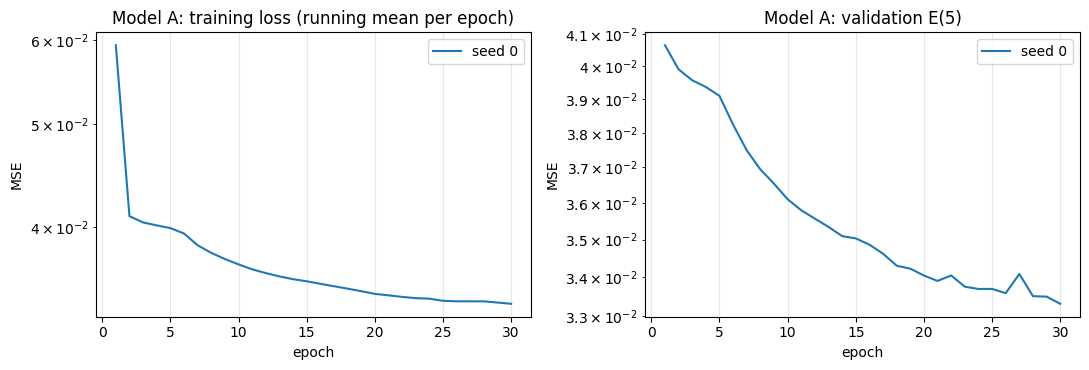

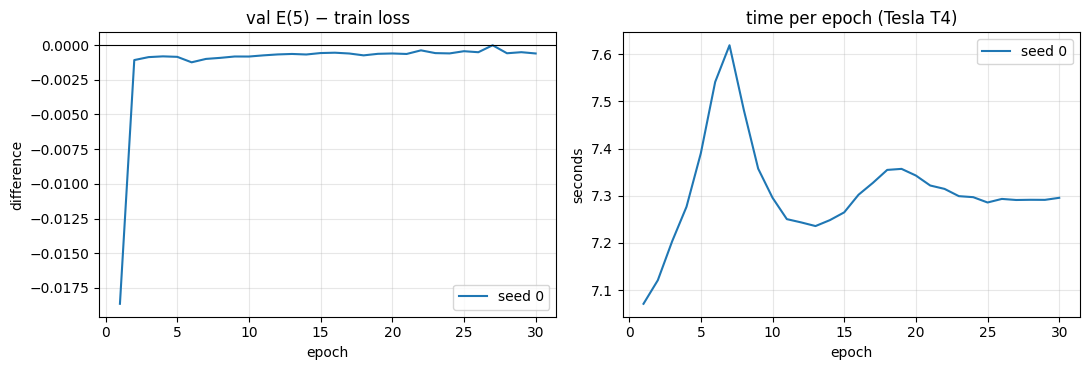

Results: ['table4.md', 'A_learning_curves.png', 'A_training.json', 'figure1.png', 'table2.md', 'figure2.png', 'A_gap_and_time.png', 'figure5.png', 'table4_raw.json', 'figure1.pdf', 'table1.csv', 'figure1_stats.json', 'table1.md', 'per_video_A_blank_copy.pt', 'table2_raw.json', 'figure3.png', 'figure1_direction_bins.csv', 'figure4.png', 'A_training_full.json', 'gifs', 'table2.csv', 'figure1_caption.txt', 'table3.md', 'table3.csv', 'table4.csv', 'A_training_summary.csv']
Seed 0 checkpoint: ['A_s0.pt']
Created: q2_results.zip and q2_ckpt.zip


In [122]:

import os, json, csv, torch
import numpy as np
import matplotlib.pyplot as plt
import shutil

CK, OUT = "/kaggle/working/ckpt", "/kaggle/working/results"
os.makedirs(OUT, exist_ok=True)

seed = 0
ck = torch.load(f"{CK}/A_s{seed}.pt", map_location="cpu", weights_only=False)
runs = {seed: ck["log"]}

hw = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"

rows = []
for s, lg in runs.items():
    rows.append(dict(
        seed=s,
        final_train_loss=lg["train_loss"][-1],
        final_val_E5=lg["val_E5"][-1],
        best_val_E5=min(lg["val_E5"]),
        best_epoch=int(np.argmin(lg["val_E5"])) + 1,
        mean_epoch_time_s=lg["mean_epoch_time"]
    ))

with open(f"{OUT}/A_training_summary.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=rows[0].keys())
    w.writeheader()
    w.writerows(rows)

with open(f"{OUT}/A_training_full.json", "w") as f:
    json.dump(
        {"hardware": hw, "logs": {str(s): lg for s, lg in runs.items()}},
        f, indent=2
    )

for r in rows:
    print({
        k: (round(v, 5) if isinstance(v, float) else v)
        for k, v in r.items()
    })

print("hardware:", hw)

ep = np.arange(1, len(runs[0]["train_loss"]) + 1)
lg = runs[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

ax[0].plot(ep, lg["train_loss"], label="seed 0")
ax[1].plot(ep, lg["val_E5"], label="seed 0")

ax[0].set_title("Model A: training loss (running mean per epoch)")
ax[1].set_title("Model A: validation E(5)")

for a in ax:
    a.set_xlabel("epoch")
    a.set_ylabel("MSE")
    a.set_yscale("log")
    a.grid(alpha=.3)
    a.legend()

plt.tight_layout()
plt.savefig(f"{OUT}/A_learning_curves.png", dpi=200)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

gap = np.array(lg["val_E5"]) - np.array(lg["train_loss"])

ax[0].plot(ep, gap, label="seed 0")
ax[0].axhline(0, color="k", lw=.8)
ax[0].set_title("val E(5) − train loss")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("difference")
ax[0].legend()
ax[0].grid(alpha=.3)

ax[1].plot(ep, lg["epoch_time"], label="seed 0")
ax[1].set_title(f"time per epoch ({hw})")
ax[1].set_xlabel("epoch")
ax[1].set_ylabel("seconds")
ax[1].legend()
ax[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig(f"{OUT}/A_gap_and_time.png", dpi=200)
plt.show()

shutil.make_archive("/kaggle/working/q2_results", "zip", OUT)

seed0_ckpt_dir = "/kaggle/working/ckpt_seed0"
os.makedirs(seed0_ckpt_dir, exist_ok=True)

shutil.copy2(
    f"{CK}/A_s0.pt",
    f"{seed0_ckpt_dir}/A_s0.pt"
)

shutil.make_archive(
    "/kaggle/working/q2_ckpt",
    "zip",
    seed0_ckpt_dir
)

print("Results:", os.listdir(OUT))
print("Seed 0 checkpoint:", os.listdir(seed0_ckpt_dir))
print("Created: q2_results.zip and q2_ckpt.zip")


In [123]:
import torch, os, csv, json
import numpy as np
from baselineConvLSTM import ConvLSTMForecaster
from train import make_windows

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT, CK = "/kaggle/working/results", "/kaggle/working/ckpt"
os.makedirs(OUT, exist_ok=True)
test_d = test.to(dev)

def load_A(seed):
    m = ConvLSTMForecaster().to(dev)
    m.load_state_dict(torch.load(f"{CK}/A_s{seed}.pt", map_location=dev, weights_only=False)["state_dict"])
    return m.eval()

@torch.no_grad()
def mse_h(predict, videos, bs=32):
    """Per-horizon MSE (5,), mean over videos; 1x, t=1: input frames 1-5, target 6-10."""
    tot = torch.zeros(5, device=dev)
    for s in range(0, len(videos), bs):
        v = torch.arange(s, min(s + bs, len(videos)), device=dev)
        X, Y, _ = make_windows(videos, v, torch.ones_like(v), torch.ones_like(v))
        tot += ((predict(X) - Y) ** 2).mean(dim=(2, 3, 4)).sum(0)
    return (tot / len(videos)).cpu().numpy()

blank = mse_h(lambda X: torch.zeros(X.shape[0], 5, *X.shape[2:], device=X.device), test_d)
copy  = mse_h(lambda X: X[:, -1:].expand(-1, 5, -1, -1, -1), test_d)
A = {s: mse_h(load_A(s), test_d) for s in (0, 1)}
nparams = sum(p.numel() for p in load_A(0).parameters())

def f3(v):                       # 3 significant figures; scientific below 1e-3
    return f"{v:.2e}" if abs(v) < 1e-3 else f"{v:.3g}"
def ms(a, b):                    # mean (seed0, seed1)
    return f"{f3((a + b) / 2)} ({f3(a)}, {f3(b)})"

hdr = ["Model"] + [f"MSE{h}" for h in range(1, 6)] + ["E(5)", "Params"]
rows = [["Blank"] + [f3(v) for v in blank] + [f3(blank.mean()), "0"],
        ["Copy-last"] + [f3(v) for v in copy] + [f3(copy.mean()), "0"],
        ["A"] + [ms(A[0][h], A[1][h]) for h in range(5)] + [ms(A[0].mean(), A[1].mean()), f"{nparams:,}"]]
for r in [hdr] + rows: print(" | ".join(r))

with open(f"{OUT}/table2.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(hdr); w.writerows(rows)
with open(f"{OUT}/table2.md", "w") as f:
    f.write("| " + " | ".join(hdr) + " |\n|" + "---|" * len(hdr) + "\n")
    for r in rows: f.write("| " + " | ".join(r) + " |\n")
json.dump({"blank": blank.tolist(), "copy_last": copy.tolist(),
           "A": {str(s): A[s].tolist() for s in A}, "params": nparams},
          open(f"{OUT}/table2_raw.json", "w"), indent=2)

Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E(5) | Params
Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0
Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0
A | 0.0297 (0.0289, 0.0304) | 0.0367 (0.036, 0.0375) | 0.0409 (0.0407, 0.0411) | 0.0418 (0.0414, 0.0422) | 0.0419 (0.0414, 0.0423) | 0.0382 (0.0377, 0.0387) | 480,784


In [124]:
dip_in  = dip[:, :5].max(1).values      # overlap in the input frames
dip_out = dip[:, 5:10].max(1).values    # overlap in the target frames

# overlap only appears in the forecast: clean inputs, clear dip in targets
cand = ((dip_in < 0.02) & (dip_out > 0.10)).nonzero().flatten()
cand = cand[dip_out[cand].argsort(descending=True)]   # strongest overlap first

# clean video: nothing overlaps anywhere in frames 1-10
clean = (dip[:, :10].max(1).values < 0.02).nonzero().flatten()

(array([224.,  16.,  17.,  11.,  21.,  22.,  29.,  24.,  19.,  29.,  21.,
         33.,  39.,  21.,  29.,  22.,  33.,  34.,  28.,  22.,  22.,  33.,
         26.,  28.,  18.,  20.,  18.,  21.,  11.,  12.,   6.,  22.,  12.,
         13.,   7.,   6.,   6.,   6.,   3.,   3.,   1.,   1.,   3.,   3.,
          0.,   2.,   1.,   1.,   0.,   1.]),
 array([0.        , 0.00637087, 0.01274173, 0.0191126 , 0.02548346,
        0.03185433, 0.0382252 , 0.04459606, 0.05096693, 0.05733779,
        0.06370866, 0.07007953, 0.07645039, 0.08282126, 0.08919213,
        0.09556299, 0.10193386, 0.10830472, 0.11467559, 0.12104646,
        0.12741733, 0.13378818, 0.14015906, 0.14652993, 0.15290079,
        0.15927166, 0.16564251, 0.17201339, 0.17838426, 0.18475512,
        0.19112599, 0.19749685, 0.20386772, 0.21023859, 0.21660945,
        0.22298032, 0.22935118, 0.23572205, 0.24209292, 0.24846378,
        0.25483465, 0.26120552, 0.26757637, 0.27394724, 0.28031811,
        0.28668898, 0.29305986, 0.2994307 , 0.

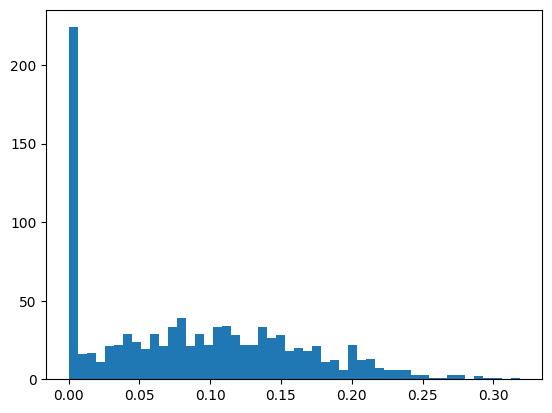

In [125]:
plt.hist(dip[:, :10].max(1).values, bins=50)

In [126]:
x = test.float() / 255                      # (1000, 20, 1, 64, 64)
mass = x.sum(dim=(2, 3, 4))                 # (1000, 20)
dip = 1 - mass / mass.max(dim=1, keepdim=True).values

dip_shown = dip[:, :10]                     # frames 1-10: inputs + targets
overlap_idx = ((dip[:, 5:10].max(1).values > 0.15)).nonzero().flatten()
clean_idx   = ((dip_shown.max(1).values < 0.02)).nonzero().flatten()

In [127]:
clean_idx

tensor([  7,  12,  14,  19,  21,  26,  29,  37,  38,  39,  44,  45,  47,  56,
         58,  61,  65,  67,  69,  71,  74,  80,  85,  87,  97,  98, 102, 104,
        107, 110, 118, 119, 125, 130, 132, 133, 139, 140, 142, 143, 147, 151,
        153, 154, 160, 171, 172, 175, 181, 184, 196, 197, 201, 203, 206, 209,
        212, 214, 215, 219, 221, 228, 230, 233, 239, 249, 256, 257, 261, 265,
        267, 271, 272, 273, 281, 283, 285, 291, 294, 296, 297, 299, 304, 306,
        314, 315, 321, 322, 324, 327, 336, 338, 341, 343, 347, 350, 351, 355,
        360, 363, 371, 392, 395, 396, 397, 404, 407, 411, 419, 420, 421, 422,
        425, 426, 428, 431, 433, 439, 444, 449, 453, 455, 458, 460, 461, 467,
        471, 472, 475, 477, 478, 482, 485, 488, 489, 491, 494, 498, 500, 502,
        505, 511, 518, 520, 523, 533, 542, 549, 553, 554, 566, 569, 571, 574,
        590, 591, 593, 594, 595, 597, 600, 602, 604, 606, 612, 615, 616, 617,
        619, 621, 622, 628, 630, 635, 637, 638, 642, 643, 644, 6

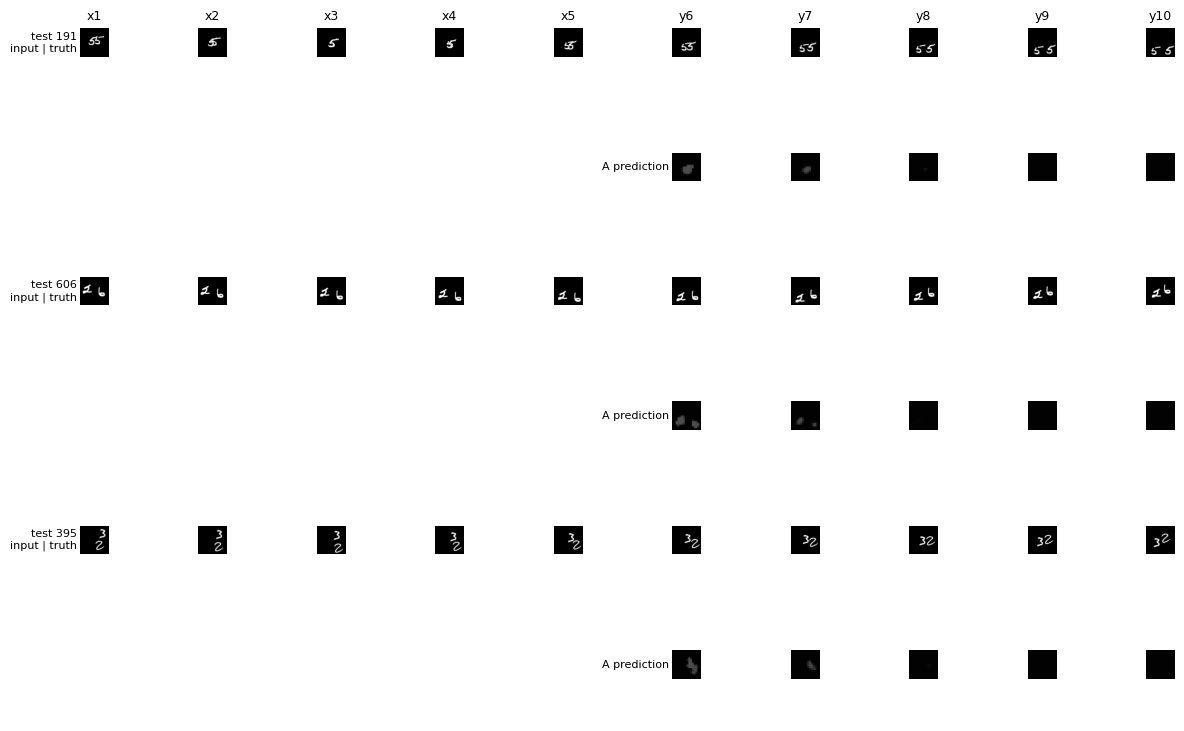

videos: [191, 606, 395]


In [128]:
chosen = [cand_overlap[0], cand_clean[0], cand_clean[1]]   # edit after looking at the gallery
mA = load_A(0)                                              # seed-0 model for figures
fig, ax = plt.subplots(2 * len(chosen), 10, figsize=(12, 2.6 * len(chosen)))
for j, vi in enumerate(chosen):
    X, Y, _ = make_windows(test_d, torch.tensor([vi], device=dev), torch.ones(1, dtype=torch.long, device=dev),
                           torch.ones(1, dtype=torch.long, device=dev))
    with torch.no_grad(): P = mA(X)
    seq = torch.cat([X[0], Y[0]]).cpu(); pr = P[0].cpu()
    for c in range(10):
        a = ax[2 * j, c]; a.imshow(seq[c, 0], cmap="gray", vmin=0, vmax=1); a.axis("off")
        if j == 0: a.set_title(f"x{c+1}" if c < 5 else f"y{c+1}", fontsize=9)
        b = ax[2 * j + 1, c]; b.axis("off")
        if c >= 5: b.imshow(pr[c - 5, 0], cmap="gray", vmin=0, vmax=1)
    ax[2 * j, 0].text(-0.1, 0.5, f"test {vi}\ninput | truth", transform=ax[2 * j, 0].transAxes,
                      ha="right", va="center", fontsize=8)
    ax[2 * j + 1, 5].text(-0.1, 0.5, "A prediction", transform=ax[2 * j + 1, 5].transAxes,
                          ha="right", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/figure2.png", dpi=200, bbox_inches="tight"); plt.show()
print("videos:", chosen)

# testing the baseline 

## table 3

In [129]:
import torch, os, csv, json
import numpy as np
from checking import M, R
from train import make_windows

Tmap = {"M": M, "R": lambda x: R(x, 1)}
D5 = (1, 2, 3, 4)

@torch.no_grad()
def per_video(predict, videos, bs=32):
    out = {k: [] for k in ("E", "CM", "EM", "CR", "ER")}
    for s in range(0, len(videos), bs):
        v = torch.arange(s, min(s + bs, len(videos)), device=videos.device)
        X, Y, _ = make_windows(videos, v, torch.ones_like(v), torch.ones_like(v))
        P = predict(X)
        out["E"].append(((P - Y) ** 2).mean(dim=D5))
        for name, T in Tmap.items():
            PT = predict(T(X))
            out["C" + name].append(((PT - T(P)) ** 2).mean(dim=D5))
            out["E" + name].append(((PT - T(Y)) ** 2).mean(dim=D5))
    return {k: torch.cat(v).cpu() for k, v in out.items()}

blank_f = lambda X: torch.zeros(X.shape[0], 5, *X.shape[2:], device=X.device)
copy_f = lambda X: X[:, -1:].expand(-1, 5, -1, -1, -1)

res = {"Blank": per_video(blank_f, test_d), "Copy-last": per_video(copy_f, test_d)}
for s in (0, 1):
    res[f"A{s}"] = per_video(load_A(s), test_d)

f3 = lambda v: f"{v:.2e}" if abs(v) < 1e-3 else f"{v:.3g}"
mean = lambda r, k: float(r[k].mean())

hdr = ["Model", "E(5)", "C_M", "E_M", "C_R", "E_R"]
keys = ["E", "CM", "EM", "CR", "ER"]
rows = []
for name in ("Blank", "Copy-last"):
    rows.append([name] + [f3(mean(res[name], k)) for k in keys])
rows.append(["A"] + [
    f"{f3((mean(res['A0'], k) + mean(res['A1'], k)) / 2)} "
    f"({f3(mean(res['A0'], k))}, {f3(mean(res['A1'], k))})"
    for k in keys
])

for r in [hdr] + rows:
    print(" | ".join(r))

OUT = "/kaggle/working/results"
with open(f"{OUT}/table3.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(hdr)
    w.writerows(rows)

with open(f"{OUT}/table3.md", "w") as f:
    f.write("| " + " | ".join(hdr) + " |\n|" + "---|" * len(hdr) + "\n")
    for r in rows:
        f.write("| " + " | ".join(r) + " |\n")

torch.save(
    {k: {kk: vv for kk, vv in v.items()} for k, v in res.items()},
    f"{OUT}/per_video_A_blank_copy.pt"
)

Model | E(5) | C_M | E_M | C_R | E_R
Blank | 0.0426 | 0.00e+00 | 0.0426 | 0.00e+00 | 0.0426
Copy-last | 0.0641 | 0.00e+00 | 0.0641 | 0.00e+00 | 0.0641
A | 0.0382 (0.0377, 0.0387) | 7.99e-05 (1.18e-04, 4.15e-05) | 0.0382 (0.0376, 0.0387) | 8.55e-05 (1.30e-04, 4.13e-05) | 0.0382 (0.0376, 0.0387)


In [130]:
sel = {"M": res["A0"]["CM"].topk(2).indices.tolist(),
       "R": res["A0"]["CR"].topk(2).indices.tolist()}
print("largest per-video C_M:", sel["M"], [f3(float(res['A0']['CM'][i])) for i in sel["M"]])
print("largest per-video C_R:", sel["R"], [f3(float(res['A0']['CR'][i])) for i in sel["R"]])

largest per-video C_M: [642, 748] ['4.30e-04', '3.75e-04']
largest per-video C_R: [84, 922] ['5.99e-04', '5.72e-04']


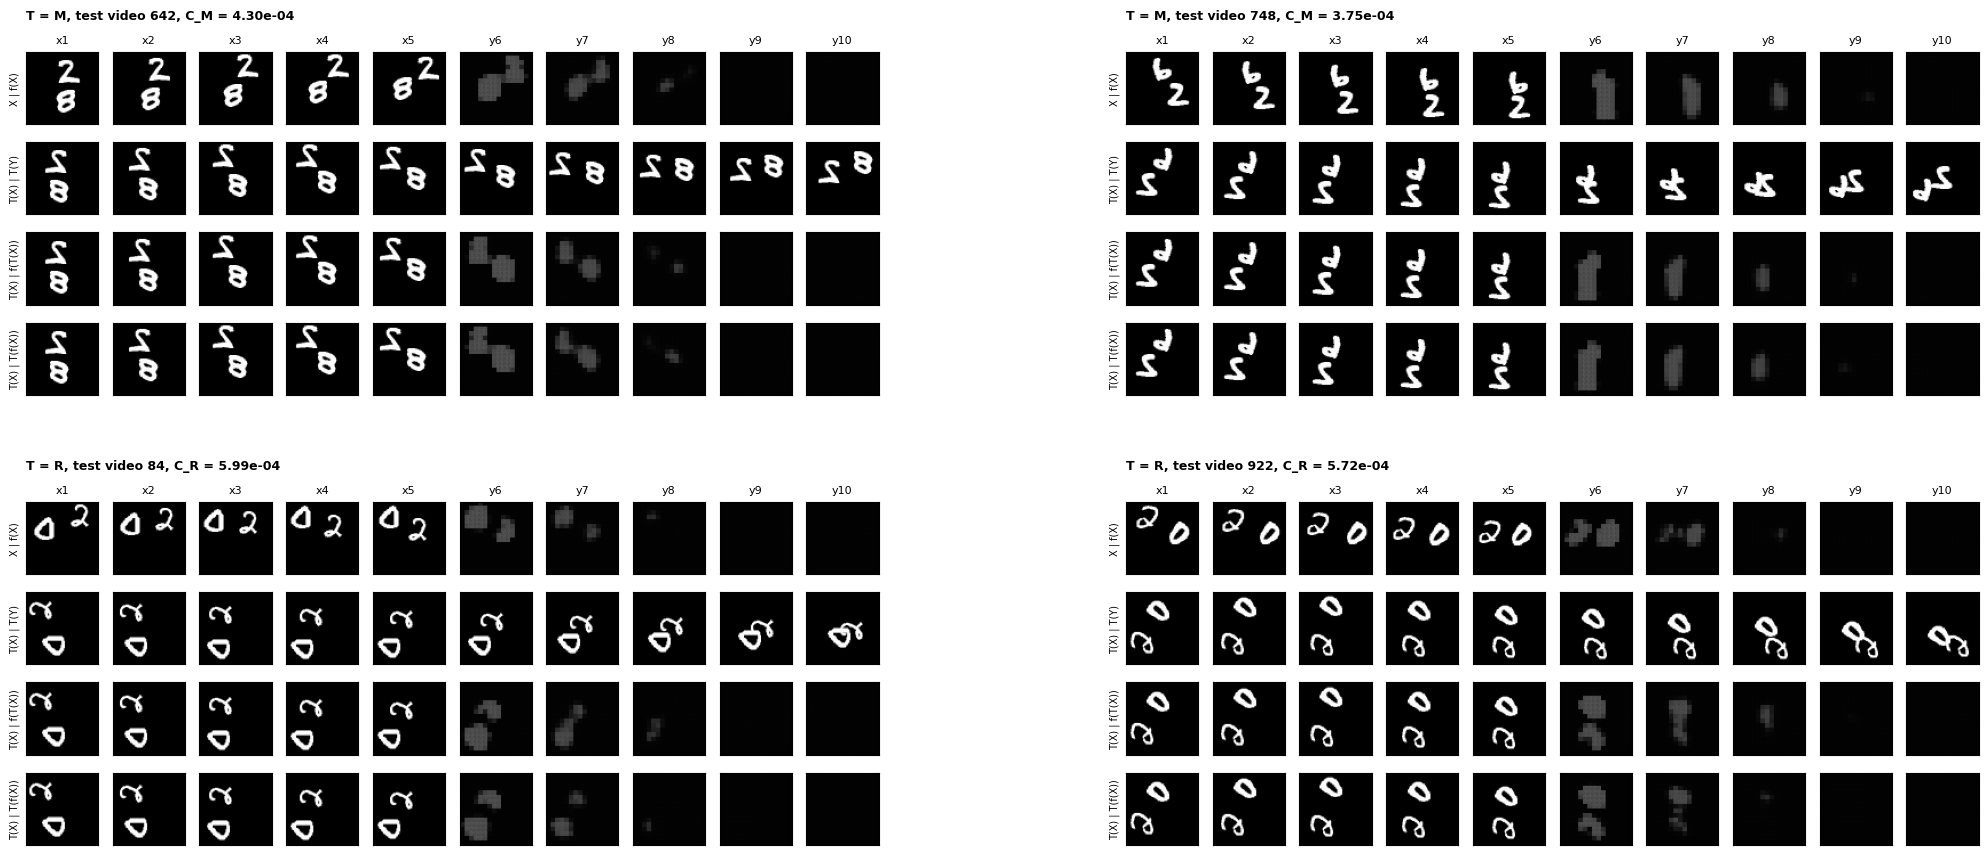

saved /kaggle/working/results/gifs/fig3_TM_video642.gif
saved /kaggle/working/results/gifs/fig3_TM_video748.gif
saved /kaggle/working/results/gifs/fig3_TR_video84.gif
saved /kaggle/working/results/gifs/fig3_TR_video922.gif


In [131]:
import matplotlib.pyplot as plt
from PIL import Image

mA = load_A(0)                                   # seed-0 model for figures
one = lambda: torch.ones(1, dtype=torch.long, device=dev)

@torch.no_grad()
def panel_data(vi, T):
    X, Y, _ = make_windows(test_d, torch.tensor([vi], device=dev), one(), one())
    P, PT = mA(X), mA(T(X))
    img = lambda a: a[0, :, 0].cpu().numpy()            # (5, 64, 64)
    TX, TY, TP = img(T(X)), img(T(Y)), img(T(P))
    # rows: (1) X | f(X)   (2) T(X) | T(Y)   (3) T(X) | f(T(X))   (4) T(X) | T(f(X))
    return [(img(X), img(P)), (TX, TY), (TX, img(PT)), (TX, TP)]

row_names = ["X | f(X)", "T(X) | T(Y)", "T(X) | f(T(X))", "T(X) | T(f(X))"]

def draw_panel(axs, rows, title, upto=5):
    for r, (left, right) in enumerate(rows):
        for c in range(10):
            a = axs[r, c]; a.clear(); a.set_xticks([]); a.set_yticks([])
            if c < 5:
                a.imshow(left[c], cmap="gray", vmin=0, vmax=1)
            elif c - 5 < upto:                         # future frames revealed up to horizon `upto`
                a.imshow(right[c - 5], cmap="gray", vmin=0, vmax=1)
            else:
                a.set_facecolor("white")
                for sp in a.spines.values(): sp.set_visible(False)
            if r == 0: a.set_title(f"x{c+1}" if c < 5 else f"y{c+1}", fontsize=8)
        axs[r, 0].set_ylabel(row_names[r], fontsize=7)
    axs[0, 0].text(0, 1.45, title, transform=axs[0, 0].transAxes, fontsize=9, weight="bold")

panels = [(name, vi) for name in ("M", "R") for vi in sel[name]]
data = {(n, vi): panel_data(vi, Tmap[n]) for n, vi in panels}
os.makedirs(f"{OUT}/gifs", exist_ok=True)

# static figure: 2x2 sub-figures, each a 4x10 panel
fig = plt.figure(figsize=(22, 9)); sfs = fig.subfigures(2, 2)
for sf, (n, vi) in zip(sfs.flat, panels):
    axs = sf.subplots(4, 10)
    cval = float(res["A0"]["C" + n][vi])
    draw_panel(axs, data[(n, vi)], f"T = {n}, test video {vi}, C_{n} = {f3(cval)}")
fig.savefig(f"{OUT}/figure3.png", dpi=170, bbox_inches="tight"); plt.show()

# GIFs: same four rows, future columns revealed horizon by horizon
for n, vi in panels:
    fig, axs = plt.subplots(4, 10, figsize=(11, 5)); frames = []
    for h in range(1, 6):
        draw_panel(axs, data[(n, vi)], f"T = {n}, test video {vi}, horizon {h}", upto=h)
        fig.canvas.draw()
        frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()))
    plt.close(fig)
    path = f"{OUT}/gifs/fig3_T{n}_video{vi}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=900, loop=0)
    print("saved", path)

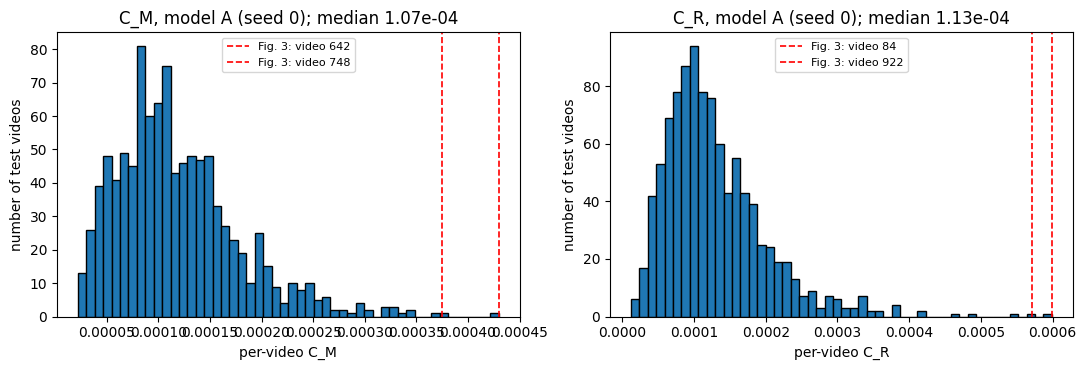

'/kaggle/working/q2_results.zip'

In [132]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, n in zip(ax, ("M", "R")):
    vals = res["A0"]["C" + n].numpy()
    a.hist(vals, bins=50, edgecolor="k")
    for i, vi in enumerate(sel[n]):
        a.axvline(vals[vi], color="r", ls="--", lw=1.2, label=f"Fig. 3: video {vi}" if True else None)
    a.set_xlabel(f"per-video C_{n}"); a.set_ylabel("number of test videos")
    a.set_title(f"C_{n}, model A (seed 0); median {f3(float(np.median(vals)))}")
    a.legend(fontsize=8)


plt.tight_layout(); plt.savefig(f"{OUT}/figure4.png", dpi=200); plt.show()

import shutil
shutil.make_archive("/kaggle/working/q2_results", "zip", OUT)

## table 4

In [133]:
import torch, csv, json, numpy as np

@torch.no_grad()
def mse_h_speed(predict, videos, k, t=1, bs=32):
    """Per-horizon MSE (5,), nan where a horizon has no target; mean over videos."""
    tot, cnt = torch.zeros(5, device=dev), torch.zeros(5, device=dev)
    for s in range(0, len(videos), bs):
        v = torch.arange(s, min(s + bs, len(videos)), device=videos.device)
        X, Y, mask = make_windows(videos, v, torch.full_like(v, k), torch.full_like(v, t))
        mse = ((predict(X) - Y) ** 2).mean(dim=(2, 3, 4))          # (B,5)
        tot += (mse * mask).sum(0); cnt += mask.sum(0)
    out = tot / cnt.clamp_min(1)
    out[cnt == 0] = float("nan")
    return out.cpu().numpy()

def e2(h): return float(h[:2].mean())
def e5(h): return float(h.mean())            # nan automatically if any horizon is missing

res4 = {"Copy-last": {k: mse_h_speed(copy_f, test_d, k) for k in (1, 2, 3)},
        "Blank":     {k: mse_h_speed(blank_f, test_d, k) for k in (1, 2, 3)}}
for s in (0, 1):
    m = load_A(s)
    res4[f"A{s}"] = {k: mse_h_speed(m, test_d, k) for k in (1, 2, 3)}

f3 = lambda v: f"{v:.2e}" if abs(v) < 1e-3 else f"{v:.3g}"
cells = [("E(2) 1x", e2, 1), ("E(2) 2x", e2, 2), ("E(2) 3x", e2, 3), ("E(5) 1x", e5, 1), ("E(5) 2x", e5, 2)]

hdr = ["Model"] + [c[0] for c in cells]
rows = []
for name in ("Copy-last", "Blank"):                       # Blank is an extra reference row
    rows.append([name] + [f3(fn(res4[name][k])) for _, fn, k in cells])
a_row = ["A"]
for _, fn, k in cells:
    a0, a1 = fn(res4["A0"][k]), fn(res4["A1"][k])
    a_row.append(f"{f3((a0 + a1) / 2)} ({f3(a0)}, {f3(a1)})")
rows.append(a_row)
for r in [hdr] + rows: print(" | ".join(r))

OUT = "/kaggle/working/results"
with open(f"{OUT}/table4.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(hdr); w.writerows(rows)
with open(f"{OUT}/table4.md", "w") as f:
    f.write("| " + " | ".join(hdr) + " |\n|" + "---|" * len(hdr) + "\n")
    for r in rows: f.write("| " + " | ".join(r) + " |\n")
json.dump({n: {str(k): v.tolist() for k, v in d.items()} for n, d in res4.items()},
          open(f"{OUT}/table4_raw.json", "w"), indent=2)

Model | E(2) 1x | E(2) 2x | E(2) 3x | E(5) 1x | E(5) 2x
Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719
Blank | 0.0426 | 0.0425 | 0.0426 | 0.0426 | 0.0425
A | 0.0332 (0.0325, 0.0339) | 0.0382 (0.0376, 0.0389) | 0.0403 (0.04, 0.0407) | 0.0382 (0.0377, 0.0387) | 0.0404 (0.0399, 0.0409)


candidates: [518, 125, 371, 449, 181, 85, 65, 74] [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


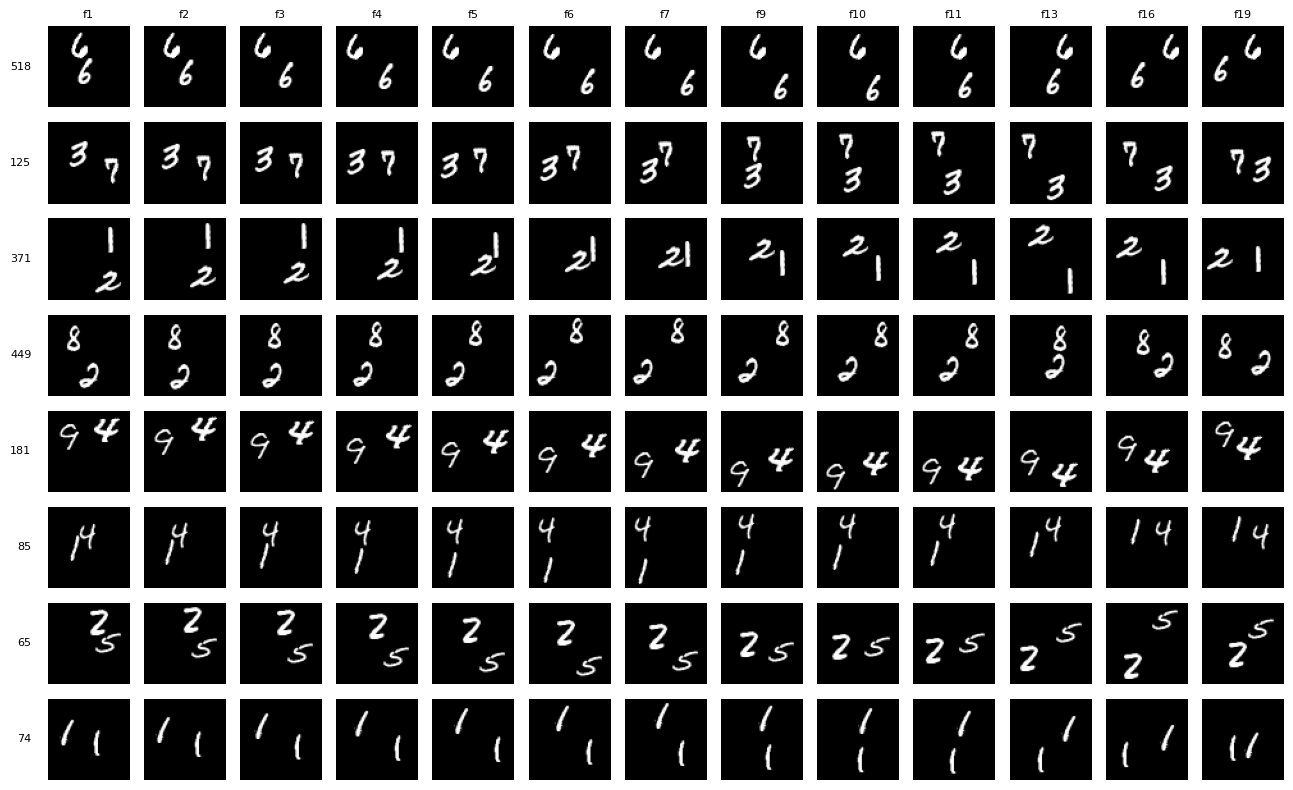

In [134]:
import matplotlib.pyplot as plt
shown = [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 16, 19]            # 1-based video frames
ink = test[:, [f - 1 for f in shown]].sum(dim=(2, 3, 4))
ratio = ink.min(1).values / ink.max(1).values
cand = ratio.argsort(descending=True)[:8].tolist()
print("candidates:", cand, [round(float(ratio[i]), 3) for i in cand])

fig, ax = plt.subplots(8, len(shown), figsize=(13, 8))
for r, vi in enumerate(cand):
    for c, f in enumerate(shown):
        ax[r, c].imshow(test[vi, f - 1, 0], cmap="gray", vmin=0, vmax=1); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(f"f{f}", fontsize=8)
    ax[r, 0].text(-0.2, 0.5, f"{vi}", transform=ax[r, 0].transAxes, ha="right", va="center", fontsize=8)
plt.tight_layout(); plt.show()

## figure 5

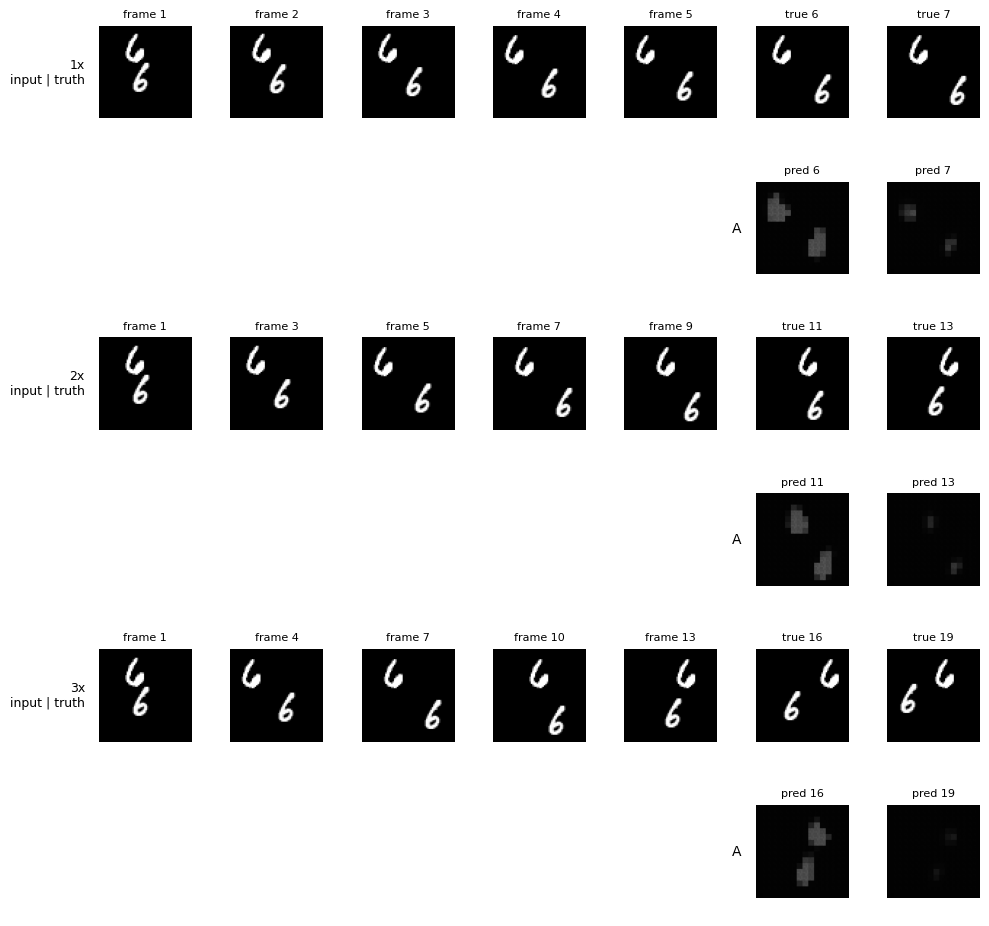

video: 518


'/kaggle/working/q2_results.zip'

In [135]:
from checking import window_frames
vi = cand[0]                      # set this to the video you chose by eye
mA = load_A(0)                    # seed-0 model for figures

fig, ax = plt.subplots(6, 7, figsize=(10, 9.5))
for j, k in enumerate((1, 2, 3)):
    one = lambda: torch.ones(1, dtype=torch.long, device=dev)
    X, Y, mask = make_windows(test_d, torch.tensor([vi], device=dev), k * one(), one())
    with torch.no_grad(): P = mA(X)
    inp, tgt = window_frames(1, k)
    for c in range(7):
        top, bot = ax[2 * j, c], ax[2 * j + 1, c]
        top.axis("off"); bot.axis("off")
        if c < 5:
            top.imshow(X[0, c, 0].cpu(), cmap="gray", vmin=0, vmax=1); top.set_title(f"frame {inp[c]}", fontsize=8)
        else:
            top.imshow(Y[0, c - 5, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            top.set_title(f"true {tgt[c - 5]}", fontsize=8)
            bot.imshow(P[0, c - 5, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            bot.set_title(f"pred {tgt[c - 5]}", fontsize=8)
    ax[2 * j, 0].text(-0.15, 0.5, f"{k}x\ninput | truth", transform=ax[2 * j, 0].transAxes,
                      ha="right", va="center", fontsize=9)
    ax[2 * j + 1, 5].text(-0.15, 0.5, "A", transform=ax[2 * j + 1, 5].transAxes, ha="right", va="center")
plt.tight_layout(); plt.savefig(f"{OUT}/figure5.png", dpi=200, bbox_inches="tight"); plt.show()
print("video:", vi)
import shutil; shutil.make_archive("/kaggle/working/q2_results", "zip", OUT)

In [136]:
for k in (1, 2, 3):
    print(f"{k}x: share of kept pixels with k*speed <= 8 px:", round(float((k * speed <= 8).mean()), 3))

1x: share of kept pixels with k*speed <= 8 px: 1.0
2x: share of kept pixels with k*speed <= 8 px: 0.797
3x: share of kept pixels with k*speed <= 8 px: 0.162


# section 4 

In [137]:
%%writefile model_d.py
import torch
from torch import nn
import torch.nn.functional as F


class ConvLSTMCellD(nn.Module):
    def __init__(self, in_ch, hid, k=3, dilation=1):
        super().__init__()
        pad = dilation * (k - 1) // 2
        self.conv = nn.Conv2d(
            in_ch + hid, 4 * hid, k, stride=1, padding=pad,
            dilation=dilation, bias=True
        )

    def forward(self, u, state):
        h, c = state
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c


class ConvLSTMForecasterD(nn.Module):
    def __init__(self, patch=4, kernels=(3, 3), dilations=(1, 1), hidden=64):
        super().__init__()
        self.patch, self.hidden = patch, hidden
        self.cell1 = ConvLSTMCellD(patch * patch, hidden, kernels[0], dilations[0])
        self.cell2 = ConvLSTMCellD(hidden, hidden, kernels[1], dilations[1])
        self.head = nn.Conv2d(hidden, patch * patch, 1)

    def forward(self, X):
        B, states, outputs, pred = X.shape[0], None, [], None
        for tau in range(9):
            frame = X[:, tau] if tau < 5 else pred
            u = F.pixel_unshuffle(frame, self.patch)
            if states is None:
                z = lambda: u.new_zeros(B, self.hidden, *u.shape[-2:])
                states = [(z(), z()), (z(), z())]
            (h1, c1), (h2, c2) = states
            h1, c1 = self.cell1(u, (h1, c1))
            h2, c2 = self.cell2(h1, (h2, c2))
            states = [(h1, c1), (h2, c2)]
            pred = torch.sigmoid(F.pixel_shuffle(self.head(h2), self.patch))
            if tau >= 4:
                outputs.append(pred)
        return torch.stack(outputs, dim=1)


def reach_px(patch=4, kernels=(3, 3), dilations=(1, 1)):
    r1, r2 = (d * (k - 1) // 2 for k, d in zip(kernels, dilations))
    return patch * (r1 + r2)

Overwriting model_d.py


In [138]:
from model_d import ConvLSTMForecasterD, reach_px
cands = {
 "D1": dict(patch=4, kernels=(3, 3), dilations=(2, 2)),
 "D2": dict(patch=4, kernels=(3, 3), dilations=(2, 3)),
 "D3": dict(patch=8, kernels=(3, 3), dilations=(1, 1)),
}
for n, kw in cands.items():
    p = sum(q.numel() for q in ConvLSTMForecasterD(**kw).parameters())
    print(n, kw, "params", f"{p:,}", "ok" if p <= 721_176 else "OVER BUDGET", "reach", reach_px(**kw), "px")

D1 {'patch': 4, 'kernels': (3, 3), 'dilations': (2, 2)} params 480,784 ok reach 16 px
D2 {'patch': 4, 'kernels': (3, 3), 'dilations': (2, 3)} params 480,784 ok reach 20 px
D3 {'patch': 8, 'kernels': (3, 3), 'dilations': (1, 1)} params 594,496 ok reach 16 px


In [139]:
%%writefile new_train.py 


import time, json, os, torch
from checking import symmetries
from baselineConvLSTM import ConvLSTMForecaster      

from model_d import ConvLSTMForecasterD

def build_model(cfg):
    if cfg.get("arch", "A") == "A":
        return ConvLSTMForecaster()
    return ConvLSTMForecasterD(**cfg["arch_kwargs"])

def make_windows(videos, vidx, k, t):
    """videos (N,20,1,64,64); vidx, k, t: (B,) long tensors (t = 1-based start frame).
    Returns X (B,5,1,64,64), Y (B,5,1,64,64) padded, mask (B,5): which targets exist."""
    ar = torch.arange(5, device=videos.device)
    base = (t - 1)[:, None]
    ii = base + k[:, None] * ar                    
    ti = base + k[:, None] * (5 + ar)              # 0-based target frame indices
    assert int(ii.max()) <= 19, "input window runs past frame 20"
    mask = ti <= 19
    X = videos[vidx[:, None], ii]
    Y = videos[vidx[:, None], ti.clamp(max=19)]    # padded entries are masked out
    return X, Y, mask


def masked_loss(pred, Y, mask):
    """Squared error averaged over pixels and the AVAILABLE targets of each video,
    then averaged over videos (every video counts equally)."""
    mse_h = ((pred - Y) ** 2).mean(dim=(2, 3, 4))          # (B,5)
    m = mask.float()
    return ((mse_h * m).sum(1) / m.sum(1)).mean()


def sample_batch(cfg, videos, vidx, gen, device):
    B = len(vidx)
    speeds = torch.tensor(cfg["speeds"])
    k = speeds[torch.randint(len(speeds), (B,), generator=gen)]
    last = (20 - 6 * k) if cfg["augmented"] else (20 - 9 * k)    # largest allowed start
    t = 1 + (torch.rand(B, generator=gen) * last).long()         # uniform over 1..last
    X, Y, mask = make_windows(videos, vidx.to(device), k.to(device), t.to(device))
    if cfg["sym_aug"]:
        g = torch.randint(8, (B,), generator=gen).to(device)     # same g for X and Y
        for gi in range(8):
            s = g == gi
            if s.any():
                X[s], Y[s] = symmetries(X[s], gi), symmetries(Y[s], gi)
    return X, Y, mask


@torch.no_grad()
def mse_per_horizon(model, videos, k=1, t=1, bs=32):
    """Mean over videos of the per-horizon pixel MSE (length 5; nan if never scored)."""
    model.eval()
    dev = next(model.parameters()).device
    tot, cnt = torch.zeros(5, device=dev), torch.zeros(5, device=dev)
    for s in range(0, len(videos), bs):
        vidx = torch.arange(s, min(s + bs, len(videos)), device=dev)
        kk = torch.full_like(vidx, k); tt = torch.full_like(vidx, t)
        X, Y, mask = make_windows(videos, vidx, kk, tt)
        mse_h = ((model(X) - Y) ** 2).mean(dim=(2, 3, 4))
        tot += (mse_h * mask).sum(0); cnt += mask.sum(0)
    return (tot / cnt.clamp_min(1)).where(cnt > 0, torch.full_like(tot, float("nan"))).cpu()



def train_one(cfg, seed, train, val, device, epochs=30, out="/kaggle/working/ckpt"):
    os.makedirs(out, exist_ok=True)
    torch.manual_seed(seed)                       # seeds initialisation (before building the model)
    model = build_model(cfg).to(device)
    gen = torch.Generator().manual_seed(seed)     # shuffling, window and augmentation sampling
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    train, val = train.to(device), val.to(device)
    log = {"epoch_time": [], "train_loss": [], "val_E5": []}
    for ep in range(epochs):
        model.train()
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        perm = torch.randperm(len(train), generator=gen)
        run, nb = 0.0, 0
        for s in range(0, len(perm), 32):
            X, Y, mask = sample_batch(cfg, train, perm[s:s + 32], gen, device)
            loss = masked_loss(model(X), Y, mask)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.item(); nb += 1
        if device.type == "cuda": torch.cuda.synchronize()
        log["epoch_time"].append(time.perf_counter() - t0)
        log["train_loss"].append(run / nb)
        log["val_E5"].append(float(mse_per_horizon(model, val).mean()))
        print(f"{cfg['name']} seed{seed} ep{ep+1:2d}  train {log['train_loss'][-1]:.5f}  "
              f"val E5 {log['val_E5'][-1]:.5f}  {log['epoch_time'][-1]:.1f}s")
    log["mean_epoch_time"] = sum(log["epoch_time"]) / epochs
    torch.save({"state_dict": model.state_dict(), "cfg": cfg, "seed": seed, "log": log},
               f"{out}/{cfg['name']}_s{seed}.pt")     # final-epoch weights only
    return model, log

Overwriting new_train.py


In [140]:
import importlib, torch
import new_train as nt                 
importlib.reload(nt)                   # pick up any edits to new_train.py
from new_train import train_one, build_model, mse_per_horizon

print(type(train), tuple(train.shape))                  # data tensor: (8000, 20, 1, 64, 64)
print("edits loaded:", hasattr(nt, "build_model"))      # should print True


from checking import symmetries
x = torch.rand(2, 5, 1, 64, 64)
for g in range(8):
    ref = torch.rot90(x, k=g % 4, dims=(-2, -1))
    if g >= 4:
        ref = torch.flip(ref, dims=(-1,))
    assert torch.equal(symmetries(x, g), ref), f"symmetries mismatch at g={g}"
print("symmetries matches G")

<class 'torch.Tensor'> (8000, 20, 1, 64, 64)
edits loaded: True
symmetries matches G


In [141]:
cfgB = dict(name="B", speeds=(1,), augmented=False, sym_aug=True)
cfgC = dict(name="C", speeds=(1, 2, 3), augmented=True, sym_aug=False)
for cfg in (cfgB, cfgC):
    for seed in (0, 1):
        train_one(cfg, seed, train, val, dev)

B seed0 ep 1  train 0.04613  val E5 0.03932  11.2s
B seed0 ep 2  train 0.03968  val E5 0.03855  11.6s
B seed0 ep 3  train 0.03868  val E5 0.03735  11.9s
B seed0 ep 4  train 0.03724  val E5 0.03557  11.6s
B seed0 ep 5  train 0.03543  val E5 0.03389  11.4s
B seed0 ep 6  train 0.03387  val E5 0.03235  11.2s
B seed0 ep 7  train 0.03238  val E5 0.03150  11.2s
B seed0 ep 8  train 0.03133  val E5 0.03032  11.3s
B seed0 ep 9  train 0.03049  val E5 0.02967  11.5s
B seed0 ep10  train 0.02983  val E5 0.02919  11.5s
B seed0 ep11  train 0.02930  val E5 0.02876  11.5s
B seed0 ep12  train 0.02891  val E5 0.02857  11.4s
B seed0 ep13  train 0.02856  val E5 0.02857  11.4s
B seed0 ep14  train 0.02831  val E5 0.02778  11.4s
B seed0 ep15  train 0.02782  val E5 0.02748  11.4s
B seed0 ep16  train 0.02756  val E5 0.02725  11.4s
B seed0 ep17  train 0.02720  val E5 0.02700  11.5s
B seed0 ep18  train 0.02690  val E5 0.02657  11.5s
B seed0 ep19  train 0.02656  val E5 0.02619  11.5s
B seed0 ep20  train 0.02623  va

In [142]:
from new_train import train_one, mse_per_horizon
trial = {}
for n, kw in cands.items():
    cfg = dict(name=f"trial_{n}", speeds=(1, 2, 3), augmented=True, sym_aug=False,
               arch="D", arch_kwargs=kw)
    m, lg = train_one(cfg, 0, train, val, dev, epochs=8, out="/kaggle/working/trials")
    h1, h3 = mse_per_horizon(m, val.to(dev), k=1), mse_per_horizon(m, val.to(dev), k=3)
    trial[n] = (float(h1.mean()), float(h3[:2].mean()), lg["mean_epoch_time"])
    print(n, "val E5@1x %.4f  val E2@3x %.4f  s/epoch %.1f" % trial[n])

trial_D1 seed0 ep 1  train 0.04670  val E5 0.03947  18.9s
trial_D1 seed0 ep 2  train 0.04019  val E5 0.03947  18.8s
trial_D1 seed0 ep 3  train 0.04019  val E5 0.03947  18.7s
trial_D1 seed0 ep 4  train 0.04019  val E5 0.03947  18.7s
trial_D1 seed0 ep 5  train 0.04018  val E5 0.03947  18.7s
trial_D1 seed0 ep 6  train 0.04018  val E5 0.03947  18.7s
trial_D1 seed0 ep 7  train 0.04018  val E5 0.03947  18.7s
trial_D1 seed0 ep 8  train 0.04019  val E5 0.03947  18.7s
D1 val E5@1x 0.0395  val E2@3x 0.0395  s/epoch 18.7
trial_D2 seed0 ep 1  train 0.04677  val E5 0.03947  18.5s
trial_D2 seed0 ep 2  train 0.04019  val E5 0.03947  18.5s
trial_D2 seed0 ep 3  train 0.04019  val E5 0.03947  18.5s
trial_D2 seed0 ep 4  train 0.04019  val E5 0.03947  18.5s
trial_D2 seed0 ep 5  train 0.04018  val E5 0.03947  18.5s
trial_D2 seed0 ep 6  train 0.04018  val E5 0.03947  18.5s
trial_D2 seed0 ep 7  train 0.04018  val E5 0.03947  18.5s
trial_D2 seed0 ep 8  train 0.04019  val E5 0.03947  18.5s
D2 val E5@1x 0.0395 

In [146]:
best = "D3"                     
cfgD = dict(name="D", speeds=(1, 2, 3), augmented=True, sym_aug=False,
            arch="D", arch_kwargs=cands[best])
for seed in (0, 1):
    train_one(cfgD, seed, train, val, dev)

D seed0 ep 1  train 0.04935  val E5 0.03948  4.1s
D seed0 ep 2  train 0.04019  val E5 0.03947  4.1s
D seed0 ep 3  train 0.04019  val E5 0.03947  4.0s
D seed0 ep 4  train 0.04019  val E5 0.03947  4.1s
D seed0 ep 5  train 0.04018  val E5 0.03947  4.2s
D seed0 ep 6  train 0.04018  val E5 0.03947  4.1s
D seed0 ep 7  train 0.04018  val E5 0.03947  4.1s
D seed0 ep 8  train 0.04019  val E5 0.03947  4.1s
D seed0 ep 9  train 0.04019  val E5 0.03947  4.1s
D seed0 ep10  train 0.04020  val E5 0.03947  4.1s
D seed0 ep11  train 0.04020  val E5 0.03947  4.1s
D seed0 ep12  train 0.04020  val E5 0.03947  4.1s
D seed0 ep13  train 0.04020  val E5 0.03947  4.0s
D seed0 ep14  train 0.04019  val E5 0.03947  4.1s
D seed0 ep15  train 0.04020  val E5 0.03947  4.1s
D seed0 ep16  train 0.04020  val E5 0.03947  4.1s
D seed0 ep17  train 0.04021  val E5 0.03947  4.1s
D seed0 ep18  train 0.04020  val E5 0.03947  4.0s
D seed0 ep19  train 0.04019  val E5 0.03947  4.0s
D seed0 ep20  train 0.04019  val E5 0.03947  4.0s


In [147]:
import time, csv, torch
from new_train import build_model, make_windows

def load_model(name, seed, d="/kaggle/working/ckpt"):
    ck = torch.load(f"{d}/{name}_s{seed}.pt", map_location=dev, weights_only=False)
    m = build_model(ck["cfg"]).to(dev); m.load_state_dict(ck["state_dict"]); return m.eval(), ck

@torch.no_grad()
def inference_time(model, videos_cpu, bs=32):
    """Seconds to predict the 1000 original test videos (1x, t=1), timed from when each batch is on device."""
    model.eval(); tot = 0.0
    for s in range(0, len(videos_cpu), bs):
        v = torch.arange(s, min(s + bs, len(videos_cpu)))
        X, _, _ = make_windows(videos_cpu, v, torch.ones_like(v), torch.ones_like(v))
        X = X.to(dev)
        if dev.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter(); model(X)
        if dev.type == "cuda": torch.cuda.synchronize()
        tot += time.perf_counter() - t0
    return tot

f3 = lambda v: f"{v:.2e}" if abs(v) < 1e-3 else f"{v:.3g}"
def ms(vals): return f"{f3(sum(vals)/len(vals))} ({', '.join(f3(v) for v in vals)})"

def evaluate(name):
    out = {k: [] for k in ["E5","CM","EM","CR","ER","E2_1","E2_2","E2_3","params","train_s","infer_s"]}
    for seed in (0, 1):
        m, ck = load_model(name, seed)
        pv = per_video(m, test_d)
        out["E5"].append(float(pv["E"].mean()))
        for k in ("CM","EM","CR","ER"): out[k].append(float(pv[k].mean()))
        for kk in (1, 2, 3): out[f"E2_{kk}"].append(float(mse_h_speed(m, test_d, kk)[:2].mean()))
        out["params"].append(sum(p.numel() for p in m.parameters()))
        out["train_s"].append(ck["log"]["mean_epoch_time"])
        inference_time(m, test[:64])                          # warm-up (excluded)
        out["infer_s"].append(inference_time(m, test))
    return out

R5 = {n: evaluate(n) for n in ("A", "B", "C", "D")}
hdr = ["Model","E(5) 1x","C_M","E_M","C_R","E_R","E(2) 1x","E(2) 2x","E(2) 3x","Params","Train s/epoch","Infer s"]
keys = ["E5","CM","EM","CR","ER","E2_1","E2_2","E2_3"]
rows = [[n] + [ms(R5[n][k]) for k in keys] + [f"{R5[n]['params'][0]:,}", ms(R5[n]["train_s"]), ms(R5[n]["infer_s"])] for n in R5]
for r in [hdr] + rows: print(" | ".join(r))
with open("/kaggle/working/results/table5.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(hdr); w.writerows(rows)

Model | E(5) 1x | C_M | E_M | C_R | E_R | E(2) 1x | E(2) 2x | E(2) 3x | Params | Train s/epoch | Infer s
A | 0.0382 (0.0377, 0.0387) | 7.99e-05 (1.18e-04, 4.15e-05) | 0.0382 (0.0376, 0.0387) | 8.55e-05 (1.30e-04, 4.13e-05) | 0.0382 (0.0376, 0.0387) | 0.0332 (0.0325, 0.0339) | 0.0382 (0.0376, 0.0389) | 0.0403 (0.04, 0.0407) | 480,784 | 7.31 (7.31, 7.31) | 0.429 (0.428, 0.431)
B | 0.0229 (0.0235, 0.0222) | 0.00126 (0.00117, 0.00135) | 0.0229 (0.0235, 0.0223) | 0.00178 (0.00181, 0.00175) | 0.0229 (0.0235, 0.0223) | 0.0191 (0.0194, 0.0189) | 0.0446 (0.044, 0.0452) | 0.0519 (0.0501, 0.0536) | 480,784 | 11.4 (11.5, 11.4) | 0.432 (0.432, 0.433)
C | 0.0276 (0.0288, 0.0264) | 0.00144 (0.00128, 0.00161) | 0.0278 (0.029, 0.0266) | 0.00262 (0.00221, 0.00302) | 0.0287 (0.0298, 0.0277) | 0.0235 (0.0242, 0.0227) | 0.0291 (0.0296, 0.0286) | 0.0335 (0.034, 0.0331) | 480,784 | 10.9 (10.9, 10.9) | 0.431 (0.43, 0.431)
D | 0.034 (0.0401, 0.0278) | 0.00103 (2.03e-06, 0.00206) | 0.0341 (0.0401, 0.0281) | 0.0

# downloaidn

In [ ]:
import os, glob, shutil, zipfile, json, platform, time
import torch
from IPython.display import FileLink, display

W = "/kaggle/working"
BUNDLE = f"{W}/q2_bundle"
shutil.rmtree(BUNDLE, ignore_errors=True)
os.makedirs(BUNDLE)

# 1. source code (the .py files you wrote with %%writefile)
os.makedirs(f"{BUNDLE}/code", exist_ok=True)
for f in glob.glob(f"{W}/*.py"):
    shutil.copy(f, f"{BUNDLE}/code/")

# 2. results: tables, figures, GIFs, JSON/CSV/MD, captions
if os.path.isdir(f"{W}/results"):
    shutil.copytree(f"{W}/results", f"{BUNDLE}/results")

# 3. checkpoints (final-epoch weights + logs) and validation-only design trials
for d in ("ckpt", "trials"):
    if os.path.isdir(f"{W}/{d}"):
        shutil.copytree(f"{W}/{d}", f"{BUNDLE}/{d}")

# 4. run info for the report (hardware, library versions)
info = {"date": time.strftime("%Y-%m-%d %H:%M"),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "torch": torch.__version__, "python": platform.python_version()}
try:
    import torchvision, cv2, matplotlib
    info.update(torchvision=torchvision.__version__, opencv=cv2.__version__, matplotlib=matplotlib.__version__)
except Exception as e:
    info["note"] = str(e)
json.dump(info, open(f"{BUNDLE}/run_info.json", "w"), indent=2)

# 5. file listing, so you can see what is in the zip
total = 0
with open(f"{BUNDLE}/MANIFEST.txt", "w") as m:
    for root, _, files in sorted(os.walk(BUNDLE)):
        for f in sorted(files):
            p = os.path.join(root, f); s = os.path.getsize(p); total += s
            m.write(f"{os.path.relpath(p, BUNDLE):70s} {s/1e6:8.2f} MB\n")
print(open(f"{BUNDLE}/MANIFEST.txt").read())
print(f"total {total/1e6:.1f} MB")

# 6. zip and link
zip_path = shutil.make_archive(f"{W}/q2_all_outputs", "zip", BUNDLE)
print("zip:", zip_path, f"{os.path.getsize(zip_path)/1e6:.1f} MB")
display(FileLink("q2_all_outputs.zip"))